In [1]:
import glob as glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import subprocess
from scipy import stats
import seaborn as sns

In [9]:
reffile = '../../../hybrid_diversity/4_flow_cytometry/pgDNA_2023paper.csv'
infiles = '../../../hybrid_diversity/4_flow_cytometry/*.CSV'
outfile = 'flow_data.Rin'

In [19]:
typeDict = {
    "8020": "HIGH",
    "8027": "HIGH",
    "12A1": "HIGH",
    "12B1": "LOW",
    "13A5": "HIGH",
    "ARC66": "HIGH",
    "ARC81": "HIGH",
    "ARC82": "HIGH",
    "ARC83": "HIGH",
    "ARC84": "HIGH",
    "CC2192B4": "LOW",
    "CC2192B5": "LOW",
    "CC2192C1": "LOW",
    "CC2192D2": "LOW",
    "CC2192D3": "LOW",
    "CCMP2941": "LOW",
    "CCMP3037": "LOW",
    "NIES1812": "LOW",
    "PK2297D4": "HIGH",
    "PK2298B4": "LOW",
    "PK2298C6": "HIGH",
    "PK2299B3": "HIGH",
    "PK2300D3": "HIGH",
    "RCC3703": "LOW",
    "UTEX2797": "HIGH",
    "UTEX2827": "HIGH"

}

strainLookup = {
    "Pp2192B4": "CC2192B4",
    "Pp2192B5": "CC2192B5",
    "Pp2192C1": "CC2192C1",
    "Pp2192D2": "CC2192D2",
    "Pp2192D3": "CC2192D3",
    "Pp2297D4": "PK2297D4",
    "Pp2298B4": "PK2298B4",
    "Pp2298C6": "PK2298C6",
    "Pp2299B3": "PK2299B3",
    "Pp2300D3": "PK2300D3"
}


In [3]:
def average_strain(instrain, df):
    values=df[df.peak==instrain]['pg dna']
    average = float(sum(values)/len(values))
    return average

def pg_mbp(pg):
    mbp = (pg*0.98E9)/(1000000)
    return mbp

# def ploidy(strain):
#     if strain == "K0081":
#         return "3C"
#     elif strain in ["12B1", "NIES1812", "Pp2298B4"]:
#         return "1C"
#     else:
#         return "2C"


In [4]:
df_2023=pd.read_csv(reffile)
_12B1=average_strain("12B1",df_2023)
CCMP3037=average_strain("CCMP3037",df_2023)
UTEX2797=average_strain("UTEX2797",df_2023)
_12A1=average_strain("12A1",df_2023)
RCC3703=average_strain("RCC3703",df_2023)
K0081=average_strain("K0081",df_2023)
#CCMP2941=average_strain("CCMP2941",df_2023)

In [5]:
print(K0081)

0.8629069506666668


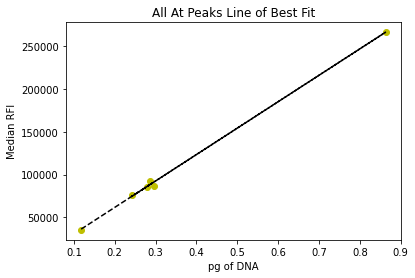

Slope of line of best fit:  308686.09314461146
Intercept of line of best fit:  -176.40800403100585


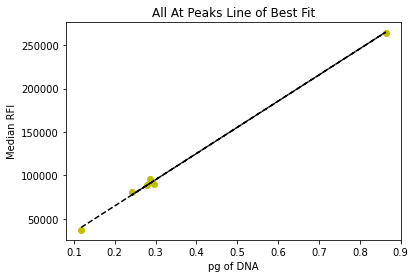

Slope of line of best fit:  301553.40600925847
Intercept of line of best fit:  4584.5841735871445


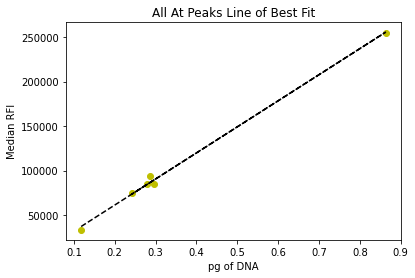

Slope of line of best fit:  292751.4649249159
Intercept of line of best fit:  2711.593515294343


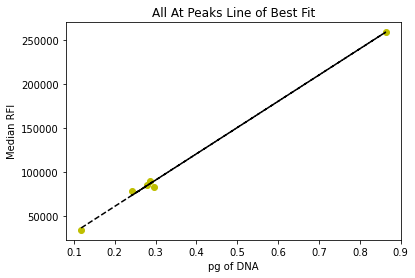

Slope of line of best fit:  298703.25939570036
Intercept of line of best fit:  1298.1629815169783


In [22]:
dfout=pd.DataFrame(columns=['Nuclei Count', 'Nuclei Median B7-A', 'Nuclei Mean B7-A', 'P1 Count', \
                            'P1 Median B7-A', 'P1 Mean B7-A', 'P2 Count', 'P2 Median B7-A', 'P2 Mean B7-A', \
                            'strain', 'Slope', 'pg DNA', 'Mbp'])

files=glob.glob(infiles)

for file in files:
    df=pd.read_csv(file)
    df[['tubeinfo','strain']]=df['Unnamed: 0'].str.split(" ", expand=True)
    df=df.drop(['Unnamed: 0', "tubeinfo"], axis=1)
    standard_RFI_values=list(df['P1 Median B7-A'])[0:6]
    standard_pg_values = [_12B1, UTEX2797, K0081, RCC3703, CCMP3037, _12A1]
    coef = np.polyfit(standard_pg_values, standard_RFI_values, 1)
    poly1d_fn = np.poly1d(coef) 
    plt.plot(standard_pg_values,standard_RFI_values, 'yo', standard_pg_values, poly1d_fn(standard_pg_values), '--k')
    ax=plt.gca()
    ax.set_xlabel('pg of DNA')
    ax.set_ylabel('Median RFI')
    ax.set_title('All At Peaks Line of Best Fit')
    plt.show()
    slope, intercept = coef
    print("Slope of line of best fit: ", slope)
    print("Intercept of line of best fit: ", intercept)
    
    df.insert(len(df.columns), "Slope", ([slope]*(len(df.index))))
    medians = df["P1 Median B7-A"]
    pg_content = []
    
    for median in medians:
        pg_converted = ((median-intercept)/slope)
        pg_content.append(pg_converted)
    
    df.insert(len(df.columns), "pg DNA", pg_content)
    mbp_content = []
    
    for pg in pg_content:
        mbp_converted = (pg*(0.98*(10**9)))/(1*(10**6))
        mbp_content.append(mbp_converted)
    
    df.insert(len(df.columns), "Mbp", mbp_content)
    dfout=pd.concat([dfout, df])

dfout.groupby(by="strain").mean()
standards=['12B1','12A1','UTEX2797','RCC3703','CCMP3037','K0081']
dfout['standard']=dfout.strain.isin(standards)
#dfout['ploidy']=dfout.strain.apply(ploidy)
dfout.reset_index(inplace=True, drop=True)


In [23]:
dfout['new strain id'] = dfout['strain'].map(strainLookup).fillna(dfout['strain'])

In [25]:
dffin = dfout[dfout['new strain id'].isin(typeDict)]

In [26]:
dffin

,Nuclei Count,Nuclei Median B7-A,Nuclei Mean B7-A,P1 Count,P1 Median B7-A,P1 Mean B7-A,P2 Count,P2 Median B7-A,P2 Mean B7-A,strain,Slope,pg DNA,Mbp,standard,new strain id
0,8963,35933,45207,7248,35292,34724,1016,71486,71696,12B1,308686.093145,0.114901,112.603193,True,12B1
1,9904,86826,108451,8476,86002,86741,889,172830,174583,UTEX2797,308686.093145,0.279178,273.594573,True,UTEX2797
3,9965,93347,114715,8758,92801,93630,720,186404,189457,RCC3703,308686.093145,0.301204,295.179672,True,RCC3703
4,5661,76608,84088,5104,76479,77745,252,154728,157384,CCMP3037,308686.093145,0.248328,243.361465,True,CCMP3037
5,9615,86987,116044,7525,86118,86392,1303,171664,172710,12A1,308686.093145,0.279554,273.962844,True,12A1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,9466,89588,94280,8996,89300,90089,447,176171,177207,8020,298703.259396,0.294613,288.720654,False,8020
83,9168,90629,100836,8223,89732,91905,888,180916,181844,UTEX2827,298703.259396,0.296059,290.137980,False,UTEX2827
84,8461,39349,43961,7505,39060,39666,922,77747,78495,NIES1812,298703.259396,0.126419,123.890849,False,NIES1812
85,8142,37663,40058,7608,37558,37699,500,74808,74827,Pp2298B4,298703.259396,0.121391,118.963015,False,PK2298B4


In [27]:
dffin.to_csv(outfile, sep="\t", index=False)

In [11]:
# #dfout.groupby(['strain']).mean()
# dfout2=dfout[['strain','pg DNA','Mbp']]
# dfout2['pg DNA']=dfout2['pg DNA'].astype(float)
# dfout2['Mbp']=dfout2['Mbp'].astype(float)
# dfout2.groupby(by='strain').std()
# #dfout.groupby(by=['strain']).mean()
# #dfg

In [12]:
# strains=['12B1','Pp2298B4','NIES1812','RCC3703','CCMP3037','Pp2192D3','Pp2192B5','Pp2192B4','Pp2192D2',\
#        'Pp2192C1','UTEX2827','8020','13A5','12A1','Pp2299B3','8027','Pp2297D4','ARC66','ARC81','ARC82',\
#        'ARC83','ARC84','ARC140','Pp2298C6','Pp2300D3','UTEX2797']#,'K0081']

# ploidypalette={"Haploid":"#BB5566","Diploid":"#DDAA33","Triploid":"#004488"}
# standardpalette={True:"#004488",False:"#DDAA33"}
# hybridpalette={"NonHybrid":"000000","H1":"#CC6677","H2":"#332288","H3":"#DDCC77","H4":"#117733"\
#                ,"H5":"#88CCEE","H6":"#882255","H7":"#44AA99"}


# sns.boxplot(data=dfout,x='strain',y='Mbp', order=strains, hue='hybrid_clade', \
#             palette=hybridpalette, fill=False, hue_order=["NonHybrid","H1","H2","H3","H4","H5","H6","H7"])


# plt.axhline(y=116, linestyle="--", c="#BBBBBB")
# plt.text(26,116,'A-type 1C')

# plt.axhline(y=np.mean([237,274,291,280]), linestyle="--", c="#BBBBBB")
# plt.text(26,np.mean([237,274,291,280]),'A-type 2C')#, fontsize=16)

# plt.xticks(rotation=90)
# plt.ylim(0,325)

# plt.legend(title="Hybrid Clade")
# plt.ylabel("Mbp DNA")
# plt.xlabel("")

# sns.set_style(style="whitegrid")

# sns.set_theme(rc={'figure.figsize':(10,5)})
# plt.tight_layout()
# plt.savefig('flow_plot_all.pdf')



In [13]:
# total_reps=list(dfout.strain)
# for strain in strains:
#     count=total_reps.count(strain)
#     print(strain, count)

In [14]:

# H1=list(dfout[dfout.strain=="UTEX2827"].Mbp)
# H2=list(dfout[dfout.strain=="8020"].Mbp)
# H3=[]
# for strain in ['13A5','12A1']:
#     H3.extend(list(dfout[dfout.strain==strain].Mbp))
# H4=[]
# for strain in ['Pp2299B3','8027','Pp2297D4']:
#     H4.extend(list(dfout[dfout.strain==strain].Mbp))
# H5=[]
# #ARC84 weird at first, not included here
# for strain in ['ARC66','ARC81','ARC82','ARC83','ARC140']:
#     H5.extend(list(dfout[dfout.strain==strain].Mbp))
# H6=[]
# for strain in ['Pp2298C6','Pp2300D3']:
#     H6.extend(list(dfout[dfout.strain==strain].Mbp))
# H7=list(dfout[dfout.strain=="UTEX2797"].Mbp)
# allhybrids=[H1,H2,H3,H4,H5,H6,H7]

In [15]:
# def bhcorr(value):
#     return ((value/49)*0.05)
# dfp=pd.DataFrame(columns=['comparison','p'])
# for compcounter in [0,1,2,3,4,5,6]:
#     compstring="H" + str(compcounter + 1) + " comparisons:"
# #    print(compstring)
#     counter = 0
#     for x in allhybrids:
#         comparison="H" + str(compcounter + 1) +" vs H"+str(counter+1)
#         p = stats.ttest_ind(allhybrids[compcounter],allhybrids[counter])[1]
# #        print(comparison, p)
#         dfp.loc[len(dfp)]=[comparison, p]
#         counter += 1
# dfp=dfp.sort_values(by="p").reset_index()
# dfp=dfp.drop(['index'], axis=1)
# dfp['rank']=dfp.index+1

# dfp['critical']=dfp['rank'].apply(bhcorr)
# dfp['significant']=dfp['p']<dfp['critical']
# dfp
# #dfp[dfp.critical.gt(dfp.p)]

In [16]:
# for compcounter in [0,1,2,3,4,5,6]:
#     compstring="H" + str(compcounter + 1) + " comparisons:"
# #    print(compstring)
#     counter = 0
#     for x in allhybrids:
#         p=stats.ttest_ind(allhybrids[compcounter],allhybrids[counter])[1]
#         if p < 0.05:
#             outstr="H" + str(compcounter + 1) +" vs H"+str(counter+1)+":"
#             print(outstr, stats.ttest_ind(allhybrids[compcounter],allhybrids[counter])[1])
#             counter += 1